# Day 2 · Notebook 3 — Navigation in the map we built: path planning (high level)

We have a **map** (Day 1) and we know **where we are** in it (Day 2). Now: how do we get to the goal?

What "planning" means depends on the map:

| map | planning space | typical planner |
|---|---|---|
| 2D occupancy grid | grid cells | Dijkstra / **A\*** |
| continuous space + collision checker (grid, voxels, mesh) | robot configurations $q$ (e.g. $x, y$ or $x, y, \theta$) | sampling-based: **PRM, RRT, RRT\*** (OMPL) |
| topological map (graph of places / images) | graph nodes | Dijkstra on the graph, then visual servoing between images |

Map: the occupancy grid of the lounge from Day 1 Notebook 4 (or a synthetic floor plan if you don't have it).

In [ ]:
# Colab / laptop: OMPL has pip wheels since v2.0 (Linux, macOS)
!pip -q install ompl

loaded occupancy_grid.npz (100, 147) 0.05 m/cell


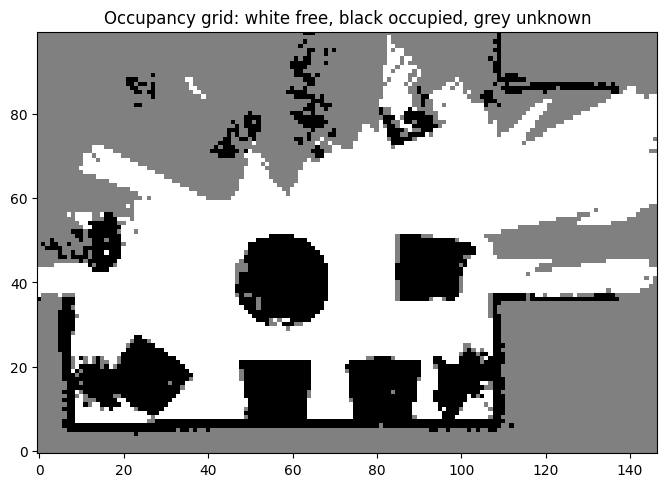

In [1]:
import heapq, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy import ndimage
from ompl import base as ob, geometric as og, util as ou
ou.setLogLevel(ou.LogLevel.LOG_ERROR)
ou.RNG.setSeed(1)                      # set once, before any planning, for repeatable results

DATA = next((p for p in [Path("data"), Path("../data")] if p.exists()), Path("data"))
grid_file = next((p for p in [Path("occupancy_grid.npz"), DATA / "lounge_occupancy.npz"] if p.exists()), None)

if grid_file is not None:
    g = np.load(grid_file)
    grid, RES, cams_cells = g["grid"], float(g["resolution"]), g["cams_cells"]   # grid[y, x]: -1 unknown, 0 free, 1 occ
    print("loaded", grid_file, grid.shape, f"{RES} m/cell")
else:
    # synthetic floor plan: 3 rooms + corridor (same conventions)
    RES = 0.05
    grid = np.zeros((100, 150), np.int8)
    grid[[0, -1], :] = 1; grid[:, [0, -1]] = 1
    grid[:, 50] = 1; grid[40:60, 50] = 0             # wall with a door
    grid[60, 50:] = 1; grid[60, 90:110] = 0          # wall with a door
    grid[20:35, 15:30] = 1; grid[70:85, 100:130] = 1 # furniture
    cams_cells = np.array([[10, 10], [25, 50], [45, 50], [75, 40], [100, 30], [100, 80], [130, 90]], float)
    print("using a synthetic floor plan")

plt.figure(figsize=(8, 6))
plt.imshow(np.where(grid == -1, 0.5, 1 - grid), origin="lower", cmap="gray", vmin=0, vmax=1)
plt.title("Occupancy grid: white free, black occupied, grey unknown"); plt.show()

## 1 · Configuration space: make the robot a point

A disc robot of radius $r$ collides exactly when its **centre** is within $r$ of an obstacle. So we **inflate** every obstacle by $r$ and plan for a point. That inflated map is the **configuration space** ($\mathcal{C}$-space): $\mathcal{C}_{free}$ vs $\mathcal{C}_{obs}$.

For non-circular robots (a car) the C-space includes the heading $\theta$, so it's 3D: $(x, y, \theta) \in SE(2)$.

We also treat **unknown** cells as obstacles (a conservative choice).

start (107, 60) goal (16, 33)


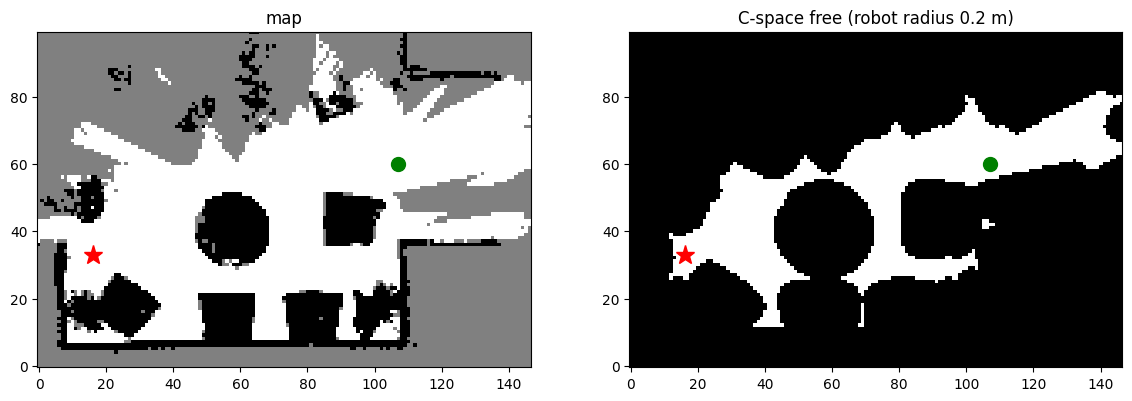

In [2]:
ROBOT_RADIUS = 0.20                                          # metres
blocked = grid != 0                                           # occupied or unknown
dist_to_obstacle = ndimage.distance_transform_edt(~blocked) * RES
cfree = dist_to_obstacle > ROBOT_RADIUS                       # C-space free cells
H, W = grid.shape

# pick start/goal: two far-apart camera positions that are free in C-space
cand = [c for c in np.round(cams_cells).astype(int) if 0 <= c[0] < W and 0 <= c[1] < H and cfree[c[1], c[0]]]
if len(cand) < 2:
    ys, xs = np.nonzero(cfree); cand = [np.array([xs[i], ys[i]]) for i in np.linspace(0, len(xs) - 1, 20).astype(int)]
cand = np.array(cand)
dmat = np.linalg.norm(cand[:, None] - cand[None], axis=-1)
i, j = np.unravel_index(np.argmax(dmat), dmat.shape)
START, GOAL = tuple(map(int, cand[i])), tuple(map(int, cand[j]))   # (x, y) in cells
print("start", START, "goal", GOAL)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
axs[0].imshow(np.where(grid == -1, 0.5, 1 - grid), origin="lower", cmap="gray"); axs[0].set_title("map")
axs[1].imshow(cfree, origin="lower", cmap="gray"); axs[1].set_title(f"C-space free (robot radius {ROBOT_RADIUS} m)")
for ax in axs:
    ax.plot(*START, "go", ms=10); ax.plot(*GOAL, "r*", ms=14)
plt.show()

## 2 · Graph search on the grid: Dijkstra and A\*

Every free cell is a node, connected to its 8 neighbours (cost 1 or $\sqrt{2}$ cells). Expand nodes in order of

$$ f(n) = g(n) + h(n) $$

* $g(n)$: cost from the start so far
* $h(n)$: estimate of the cost to the goal. $h = 0$ gives **Dijkstra**; straight-line distance gives **A\***.
* If $h$ never overestimates (**admissible**), A\* still returns the **optimal** path, but expands far fewer nodes.

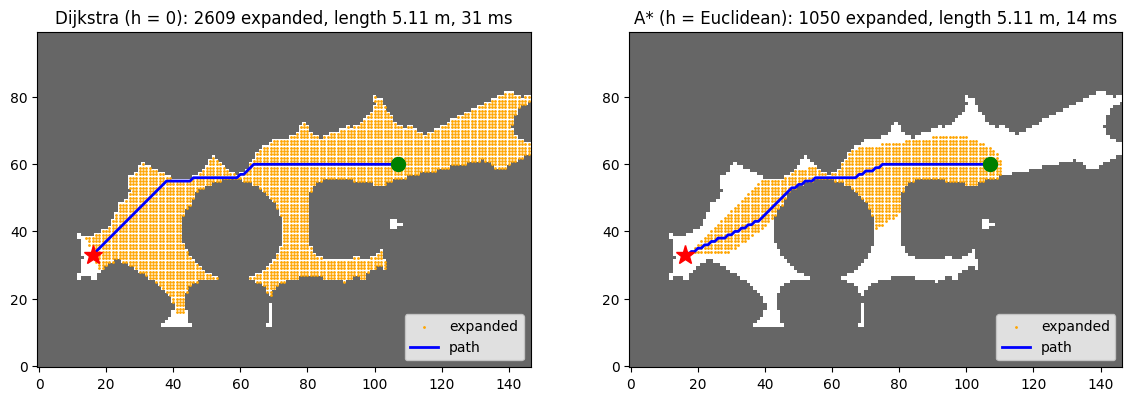

In [3]:
NBRS = [(dx, dy, np.hypot(dx, dy)) for dx in (-1, 0, 1) for dy in (-1, 0, 1) if (dx, dy) != (0, 0)]

def astar(free, start, goal, use_heuristic=True):
    h = (lambda p: np.hypot(p[0] - goal[0], p[1] - goal[1])) if use_heuristic else (lambda p: 0.0)
    g_cost, parent, closed = {start: 0.0}, {start: None}, set()
    pq = [(h(start), start)]
    while pq:
        _, cur = heapq.heappop(pq)
        if cur in closed: continue
        closed.add(cur)
        if cur == goal: break
        for dx, dy, c in NBRS:
            nb = (cur[0] + dx, cur[1] + dy)
            if not (0 <= nb[0] < free.shape[1] and 0 <= nb[1] < free.shape[0]) or not free[nb[1], nb[0]]:
                continue
            ng = g_cost[cur] + c
            if ng < g_cost.get(nb, np.inf):
                g_cost[nb], parent[nb] = ng, cur
                heapq.heappush(pq, (ng + h(nb), nb))
    path, p = [], goal
    while p is not None and p in parent:
        path.append(p); p = parent[p]
    return np.array(path[::-1]), closed, g_cost.get(goal, np.inf)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, use_h, name in [(axs[0], False, "Dijkstra (h = 0)"), (axs[1], True, "A* (h = Euclidean)")]:
    t0 = time.time(); path, closed, cost = astar(cfree, START, GOAL, use_h); dt = time.time() - t0
    ax.imshow(cfree, origin="lower", cmap="gray", alpha=0.6)
    cl = np.array(list(closed)); ax.scatter(cl[:, 0], cl[:, 1], s=1, c="orange", label="expanded")
    ax.plot(path[:, 0], path[:, 1], "b-", lw=2, label="path")
    ax.plot(*START, "go", ms=10); ax.plot(*GOAL, "r*", ms=14)
    ax.set_title(f"{name}: {len(closed)} expanded, length {cost * RES:.2f} m, {1000*dt:.0f} ms"); ax.legend(loc="lower right")
plt.show()

## 3 · Sampling-based planning with OMPL

Grids get huge in higher dimensions (a 7-DOF arm, or $x, y, z, \text{yaw}$ for a drone). **Sampling-based** planners only need a **collision checker** `is_valid(q)`:

* **PRM** (Kavraki et al. 1996): sample many free configurations, connect neighbours with collision-free straight lines into a *roadmap*, then run graph search. Good for many queries in the same map.
* **RRT** (LaValle 1998): grow a tree from the start. Sample $q_{rand}$, extend the nearest tree node a step towards it. Finds *a* path fast. Not optimal.
* **RRT\*** (Karaman & Frazzoli 2011): RRT + *rewiring* of nearby nodes, so the path cost converges to the optimum as samples go to infinity (**asymptotically optimal**).

OMPL (Open Motion Planning Library, Şucan, Moll, Kavraki 2012) provides all of these. MoveIt and Nav2 use it. We plan in $\mathbb{R}^2$ (metres) using the C-space grid as the collision checker.

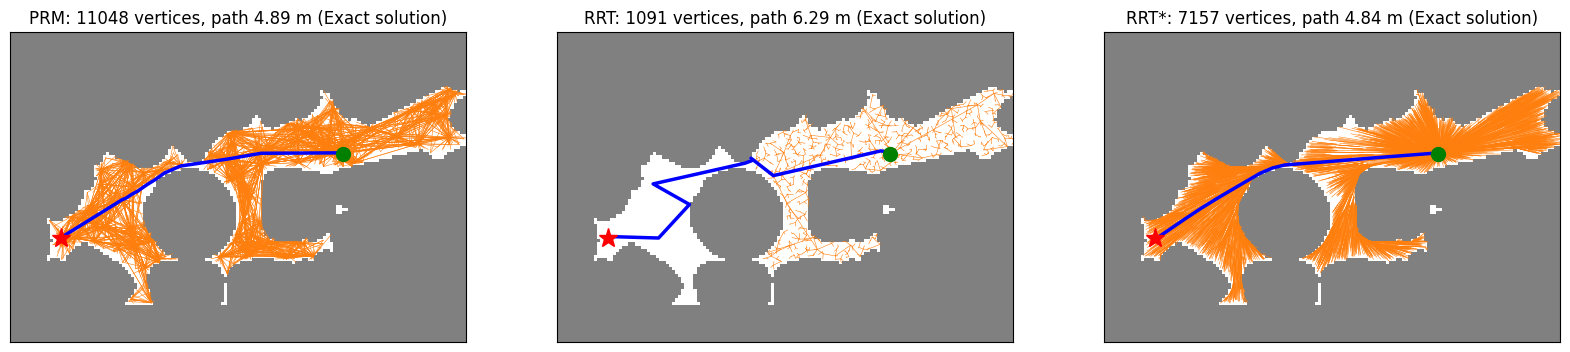

In [4]:
def is_valid(state):
    x, y = state[0] / RES, state[1] / RES                    # metres -> cells
    xi, yi = int(x), int(y)
    return 0 <= xi < W and 0 <= yi < H and bool(cfree[yi, xi])

def plan_ompl(planner_cls, time_limit=1.0):
    space = ob.RealVectorStateSpace(2)
    bounds = ob.RealVectorBounds(2)
    bounds.setLow(0, 0.0); bounds.setHigh(0, W * RES); bounds.setLow(1, 0.0); bounds.setHigh(1, H * RES)
    space.setBounds(bounds)
    ss = og.SimpleSetup(space)
    ss.setStateValidityChecker(is_valid)
    si = ss.getSpaceInformation()
    si.setStateValidityCheckingResolution(0.005)            # check edges every 0.5% of the space extent
    start, goal = space.allocState(), space.allocState()
    start[0], start[1] = (START[0] + 0.5) * RES, (START[1] + 0.5) * RES
    goal[0], goal[1] = (GOAL[0] + 0.5) * RES, (GOAL[1] + 0.5) * RES
    ss.setStartAndGoalStates(start, goal, 0.05)
    ss.setOptimizationObjective(ob.PathLengthOptimizationObjective(si))
    planner = planner_cls(si)
    ss.setPlanner(planner)
    solved = ss.solve(time_limit)
    path = np.array([[s[0], s[1]] for s in ss.getSolutionPath().getStates()]) / RES if solved else None
    pd = ob.PlannerData(si); ss.getPlannerData(pd)
    verts = np.array([[pd.getVertex(k).getState()[0], pd.getVertex(k).getState()[1]]
                      for k in range(pd.numVertices())]) / RES
    edges = [(a, b) for a in range(pd.numVertices()) for b in pd.getEdges(a)]
    length = ss.getSolutionPath().length() if solved else np.inf
    return path, verts, edges, length, str(solved)

fig, axs = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, (cls, name, tl) in zip(axs, [(og.PRM, "PRM", 1.0), (og.RRT, "RRT", 1.0), (og.RRTstar, "RRT*", 1.0)]):
    path, verts, edges, length, status = plan_ompl(cls, tl)
    ax.imshow(cfree, origin="lower", cmap="gray", alpha=0.5)
    for a, b in edges[:6000]:
        ax.plot(verts[[a, b], 0], verts[[a, b], 1], "-", color="tab:orange", lw=0.4)
    if path is not None:
        ax.plot(path[:, 0], path[:, 1], "b-", lw=2.5)
    ax.plot(*START, "go", ms=10); ax.plot(*GOAL, "r*", ms=14)
    ax.set_title(f"{name}: {len(verts)} vertices, path {length:.2f} m ({status})"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlim(-0.5, W - 0.5); ax.set_ylim(-0.5, H - 0.5)
plt.show()

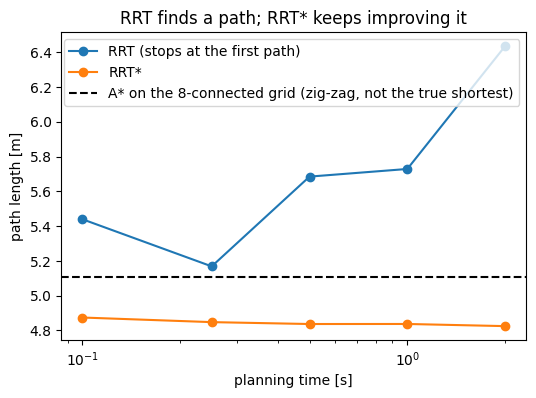

In [5]:
# RRT* is "anytime": give it more time and the path keeps getting shorter
times = [0.1, 0.25, 0.5, 1.0, 2.0]
lengths = {name: [np.mean([plan_ompl(cls, t)[3] for _ in range(3)]) for t in times]
           for cls, name in [(og.RRT, "RRT (stops at the first path)"), (og.RRTstar, "RRT*")]}
_, _, a_star_cost = astar(cfree, START, GOAL, True)
plt.figure(figsize=(6, 4))
for name, L in lengths.items():
    plt.plot(times, L, "o-", label=name)
plt.axhline(a_star_cost * RES, color="k", ls="--", label="A* on the 8-connected grid (zig-zag, not the true shortest)")
plt.xscale("log"); plt.xlabel("planning time [s]"); plt.ylabel("path length [m]"); plt.legend()
plt.title("RRT finds a path; RRT* keeps improving it"); plt.show()

## 4 · Planning on a topological map

A **topological map** has no global geometry, only **places** (nodes: here, the keyframes where the camera was) and **"I can go from here to there"** edges.

* Planning = **shortest path on the graph** (Dijkstra). The answer is a **sequence of places/images** to visit.
* Executing it = a local controller that drives from the current view towards the next *subgoal image* (visual servoing / a learned image-goal policy). That's the topic of the main lecture.

Here the nodes are the Day-1 camera positions (the ones where the robot fits). Two places get an edge if the robot can drive between them in less than 1.5 m. (In a real system: the two images are visually connected / a local controller can go from one to the other.)

graph: 38 places, 287 edges; route 8 -> 57: [8, 7, 38, 36, 55, 57]


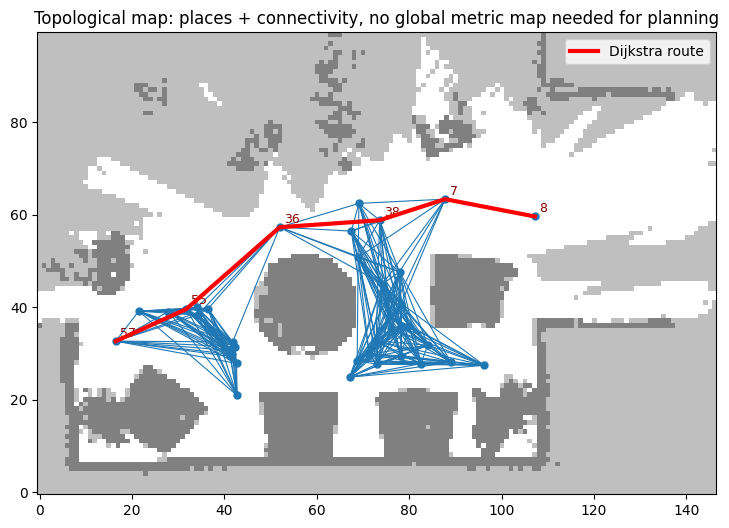

In [6]:
# keep only places where the robot itself can stand (the hand-held camera was sometimes above furniture)
c_int = np.round(cams_cells).astype(int)
inside_map = (c_int[:, 0] >= 0) & (c_int[:, 0] < W) & (c_int[:, 1] >= 0) & (c_int[:, 1] < H)
place_ids = [k for k in range(len(cams_cells)) if inside_map[k] and cfree[c_int[k, 1], c_int[k, 0]]]
nodes = cams_cells

# edge = "the robot can drive from place a to place b within 1.5 m" (checked with A* on the C-space grid)
MAX_EDGE = 1.5
G = nx.Graph()
for ia, a in enumerate(place_ids):
    G.add_node(a, pos=nodes[a])
    for b in place_ids[ia + 1:]:
        if np.linalg.norm(nodes[a] - nodes[b]) * RES > MAX_EDGE:
            continue
        _, _, cost = astar(cfree, tuple(map(int, c_int[a])), tuple(map(int, c_int[b])))
        if cost * RES < MAX_EDGE:
            G.add_edge(a, b, weight=cost * RES)

comp = max(nx.connected_components(G), key=len)
far = max(((a, b) for a in comp for b in comp), key=lambda ab: np.linalg.norm(nodes[ab[0]] - nodes[ab[1]]))
route = nx.shortest_path(G, *far, weight="weight")
print(f"graph: {G.number_of_nodes()} places, {G.number_of_edges()} edges; route {far[0]} -> {far[1]}: {route}")

plt.figure(figsize=(9, 6))
plt.imshow(np.where(grid == -1, 0.5, 1 - grid), origin="lower", cmap="gray", alpha=0.5)
for a, b in G.edges:
    plt.plot(nodes[[a, b], 0], nodes[[a, b], 1], "-", color="tab:blue", lw=0.8)
plt.scatter(nodes[place_ids, 0], nodes[place_ids, 1], s=25, c="tab:blue", zorder=3)
plt.plot(nodes[route, 0], nodes[route, 1], "r-", lw=3, zorder=4, label="Dijkstra route")
for k, r in enumerate(route):
    plt.text(nodes[r, 0] + 1, nodes[r, 1] + 1, str(r), color="darkred", fontsize=9)
plt.legend(); plt.title("Topological map: places + connectivity, no global metric map needed for planning")
plt.show()

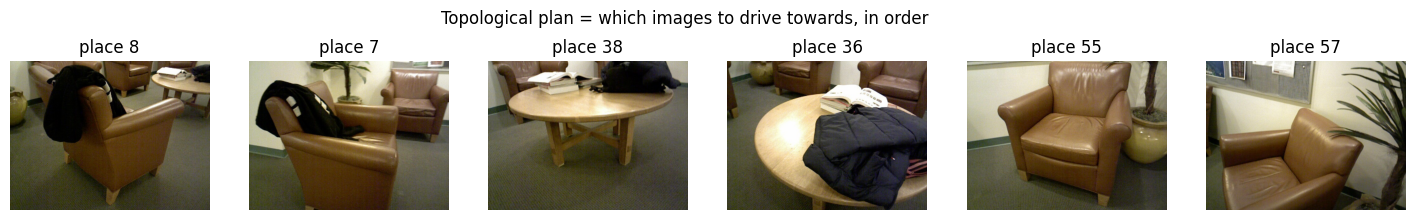

In [7]:
# The plan as a robot with a camera would see it: a sequence of SUBGOAL IMAGES
color_dir = DATA / "lounge_rgbd" / "color"
if color_dir.exists() and grid_file is not None:
    show = route if len(route) <= 8 else [route[int(k)] for k in np.linspace(0, len(route) - 1, 8)]
    fig, axs = plt.subplots(1, len(show), figsize=(3 * len(show), 2.6))
    for ax, r in zip(np.atleast_1d(axs), show):
        ax.imshow(plt.imread(color_dir / f"{r:03d}.jpg")); ax.set_title(f"place {r}"); ax.axis("off")
    plt.suptitle("Topological plan = which images to drive towards, in order"); plt.show()
else:
    print("(lounge images not found: skipping the subgoal-image strip)")

## Takeaways

* **Metric map** → plan in C-space: A\* on grids, PRM/RRT/RRT\* (OMPL) when the space is continuous or high-dimensional.
* **Topological map** → plan on the place graph (Dijkstra); the hard part moves to the **local controller** that reaches each subgoal image.
* Real navigation stacks (e.g. ROS 2 Nav2) combine a **global planner** on the map with a **local planner/controller** (DWA, MPC) that reacts to what the sensors see right now.

**Read more:** LaValle, *Planning Algorithms* (free online), ch. 5 · Siegwart, Nourbakhsh & Scaramuzza, *Introduction to Autonomous Mobile Robots*, ch. 6 · Karaman & Frazzoli, IJRR 2011.